# FarmTech Solutions — Ir Além (Opção 3.2)
## Transfer Learning, Fine Tuning e segmentação automática

**Integrantes do grupo:**
- Caroline Coelho Mendes — RM570370
- Leandro Paiva — RM572159
- Lucas Viana de Lima — RM571835

**Disciplina:** Fase 06 — Cap. 1 — O despertar da Rede Neural  
**Classes:** `0 = vaca`, `1 = equipamento_pesado`  
**Base:** as mesmas 80 imagens do projeto principal, com divisão fixa de **64 treino / 8 validação / 8 teste**.

### Perguntas investigadas

1. **Transfer Learning:** uma MobileNetV2 pré-treinada na ImageNet e ajustada com Fine Tuning supera a CNN pequena treinada do zero na Entrega 2?
2. **Segmentação:** classificar imagens com o fundo removido automaticamente melhora os acertos em relação a usar a imagem inteira? Testamos essa pergunta com **as duas redes de classificação** que o enunciado permite:
   - a **MobileNetV2** (Transfer Learning), com os mesmos hiperparâmetros nas duas versões;
   - a **CNN do zero** (mesma arquitetura da Entrega 2), repetida com **5 sementes** em cada versão, porque uma única rodada de uma rede pequena varia muito.

Todos os experimentos classificam **a imagem inteira em uma única classe**. A YOLO do projeto principal, por sua vez, detecta objetos e caixas; as métricas das duas tarefas não são intercambiáveis.

> **Integridade experimental:** a segmentação usa previsões da YOLO customizada como *prompts* para o SAM 2. **Os rótulos reais de validação e teste nunca são usados para escolher caixas ou gerar máscaras.** Falhas de segmentação, se houver, permanecem na avaliação. As 80 anotações originais não são modificadas.

**Documentação consultada:** [Transfer learning e fine tuning — TensorFlow](https://www.tensorflow.org/tutorials/images/transfer_learning); [MobileNetV2 — API TensorFlow](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2); [SAM 2 — Ultralytics](https://docs.ultralytics.com/models/sam-2).

## 1. Fluxograma autoral da solução

A figura mostra os dois caminhos de pré-processamento — **imagem inteira** e **fundo removido** — aplicados às **mesmas imagens e à mesma divisão**. Em cada caminho rodamos os mesmos dois classificadores (MobileNetV2 com Transfer Learning e CNN do zero). O único fator que muda entre os caminhos é a remoção do fundo.

![Fluxograma autoral](figura_metodologia.png)

O caminho com máscara depende de duas redes adicionais **já treinadas**: a YOLO customizada (localiza o objeto automaticamente) e o SAM 2 (segmenta). Essa dependência entra nas limitações e no tempo de inferência total.

## 2. Preparar o Colab e encontrar o dataset e o checkpoint

1. Ative **GPU T4** em *Ambiente de execução → Alterar tipo de ambiente*.
2. O notebook procura o dataset em `Meu Drive/FarmTech_Fase6/dataset_yolo`. Se não o encontrar, tenta um ZIP do projeto no Drive ou em `/content` (inclusive o **Download ZIP** do GitHub), depois o repositório em `REPO_GITHUB` e, por fim, pede o upload do ZIP.
3. Se existir o checkpoint YOLO de **60 épocas** em `Meu Drive/FarmTech_Fase6/resultados_revisao/yolo_custom/epocas_60/weights/best.pt`, ele é reutilizado. Se faltar, o notebook treina uma YOLO auxiliar **sem usar as imagens de teste** (mais demorado).
4. Rode as células **em ordem**. Os arquivos novos vão para `Meu Drive/FarmTech_Fase6/resultados_ir_alem/`. Modelos já treinados são reaproveitados (`REFAZER_TREINOS`, `REFAZER_CNN`), para que os números citados correspondam aos modelos avaliados.

O SAM 2 baixa um checkpoint público na primeira execução. O tempo de download e preparo não é contado como tempo de treinamento.

In [1]:
# ── Dependências (a instalação pode levar alguns minutos na 1ª execução) ──
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.3,<9',
                'scikit-learn', 'pandas', 'pillow', 'matplotlib'], check=True)   # SAM 2 vem do ultralytics
from pathlib import Path
import os, re, json, time, random, shutil, zipfile, gc, hashlib
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import drive

drive.mount('/content/drive')                     # acesso ao Meu Drive
SEED = 42                                         # mesma semente do projeto principal
random.seed(SEED); np.random.seed(SEED)

# ── Pastas ──────────────────────────────────────────────────────────────
ROOT = Path('/content/drive/MyDrive/FarmTech_Fase6')
SRC = ROOT / 'dataset_yolo'                       # dataset original (imagens + rótulos)
OUT = ROOT / 'resultados_ir_alem'                 # saídas deste notebook
OUT.mkdir(parents=True, exist_ok=True)
LOCAL = Path('/content/farmtech_ir_alem')         # cache local de originais, máscaras e recortes
LOCAL.mkdir(parents=True, exist_ok=True)
REPO_GITHUB = ''  # link do repositório do grupo (usado só se o dataset não estiver no Drive)

# ── Parâmetros dos experimentos ─────────────────────────────────────────
CLASSES = ['vaca', 'equipamento_pesado']
SPLITS = {'train': 64, 'val': 8, 'test': 8}
MAX_SIDE = 768                 # resolução máxima usada na segmentação
SIZE = (224, 224)              # entrada da MobileNetV2 (padrão ImageNet)
BATCH_SIZE = 8
EPOCHS_CABECALHO = 15          # fase 1: só o classificador novo
EPOCHS_FINE = 15               # fase 2: Fine Tuning
FINE_LAST_LAYERS = 30          # camadas finais liberadas no Fine Tuning
CONF_DETECTOR = 0.15           # confiança mínima da YOLO para propor a caixa ao SAM 2
CNN_SIZE = (150, 150)          # entrada da CNN do zero (igual à Entrega 2)
SEMENTES_CNN = [42, 7, 123, 2024, 99]   # repetições da CNN do zero em cada versão
REFAZER_MASCARAS = False       # True: recalcula as máscaras
REFAZER_TREINOS = False        # True: refaz as duas MobileNetV2
REFAZER_CNN = False            # True: refaz as 10 rodadas da CNN do zero
AUTO_TREINAR_YOLO_SE_FALTAR = True  # permite reproduzir sem o checkpoint do notebook principal

# ── Localizar o dataset: Drive → ZIP → GitHub → upload ─────────────────
# Reconhece o ZIP original (FarmTech_Fase6/...) e também o ZIP do botão
# "Code → Download ZIP" do GitHub (NomeDoRepo-main/...).
IMAGENS_TREINO = re.compile(r'^(.*?)dataset_yolo/images/train/[^/]+\.(jpe?g|png|webp|bmp)$', re.I)

def copiar_dataset(origem, destino):
    """Copia a pasta dataset_yolo encontrada para o Drive, substituindo cópias incompletas."""
    if destino.exists():
        shutil.rmtree(destino)
    shutil.copytree(origem, destino)
    print(f'Dataset copiado para: {destino}')

def dataset_de_zip(arquivo, destino):
    """Extrai somente a pasta dataset_yolo de um ZIP, qualquer que seja a pasta-raiz."""
    try:
        with zipfile.ZipFile(arquivo) as z:
            # descobre o prefixo (pasta-raiz) que antecede dataset_yolo/
            prefixo = next((m.group(1) for n in z.namelist() if (m := IMAGENS_TREINO.match(n))), None)
            if prefixo is None:
                return False                                   # este ZIP não tem o dataset
            temp = Path('/content/_extracao_dataset')
            if temp.exists():
                shutil.rmtree(temp)
            for info in z.infolist():
                if info.filename.startswith(prefixo + 'dataset_yolo/'):
                    alvo = (temp / info.filename).resolve()
                    assert temp.resolve() in alvo.parents, f'Caminho inseguro no ZIP: {info.filename}'
                    z.extract(info, temp)                      # extrai arquivo por arquivo
        copiar_dataset(temp / prefixo / 'dataset_yolo', destino)
        return True
    except (zipfile.BadZipFile, OSError):
        return False

def obter_dataset(destino):
    """Garante destino/images/train. Ordem de busca: Drive, ZIP no Drive/Colab, git clone, upload."""
    if (destino / 'images' / 'train').is_dir():
        print(f'Dataset encontrado no Drive: {destino}')
        return
    pastas = [ROOT.parent, ROOT, Path('/content'), ROOT.parent / 'Downloads']
    zips = sorted({p for pasta in pastas if pasta.is_dir() for p in pasta.glob('*.zip')},
                  key=lambda p: p.stat().st_mtime, reverse=True)       # ZIPs mais recentes primeiro
    for arquivo in zips:
        if dataset_de_zip(arquivo, destino):
            print(f'Dataset extraído de: {arquivo}')
            return
    if REPO_GITHUB:                                                    # clona o repositório do grupo
        repo = Path('/content/repo_farmtech')
        if repo.exists():
            shutil.rmtree(repo)
        subprocess.run(['git', 'clone', '--depth', '1', REPO_GITHUB, str(repo)], check=True)
        achado = next((p for p in repo.rglob('dataset_yolo') if (p / 'images' / 'train').is_dir()), None)
        if achado is not None:
            copiar_dataset(achado, destino)
            return
    from google.colab import files                                     # último recurso: upload
    print('Dataset não encontrado. Selecione o ZIP do projeto (pacote original ou Download ZIP do GitHub):')
    for nome in files.upload():
        if dataset_de_zip(Path('/content') / nome, destino):
            return
    raise FileNotFoundError('Nenhuma fonte com dataset_yolo/images/train foi encontrada.')


obter_dataset(SRC)
print('Saídas do Ir Além:', OUT)

Mounted at /content/drive
Dataset encontrado no Drive: /content/drive/MyDrive/FarmTech_Fase6/dataset_yolo
Saídas do Ir Além: /content/drive/MyDrive/FarmTech_Fase6/resultados_ir_alem


## 3. Auditoria das 80 imagens (sem usar rótulos na segmentação)

A **classe verdadeira de cada imagem** é lida do label YOLO exclusivamente para treinar e avaliar a **classificação**. Ela não participa da escolha da região que será segmentada. Garantimos a mesma ordem e os mesmos 8 exemplos de teste em todas as condições.

As fotos são redimensionadas mantendo a proporção antes da segmentação; as caixas previstas pela YOLO usam essa mesma resolução. O dataset original no Drive permanece intocado.

In [2]:
# ── Inventário das imagens, conferência da divisão 32/4/4 por classe ───
EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
rows = []
for split, n in SPLITS.items():
    pasta_imagens = SRC / 'images' / split
    pasta_rotulos = SRC / 'labels' / split
    assert pasta_imagens.exists() and pasta_rotulos.exists(), f'Pasta ausente: {split}'
    ims = sorted(p for p in pasta_imagens.iterdir() if p.suffix.lower() in EXT)
    assert len(ims) == n, f'{split}: {len(ims)} imagens; esperado {n}'
    stems = [p.stem for p in ims]
    assert len(stems) == len(set(stems)), f'Nomes duplicados em {split}'
    assert {p.stem for p in pasta_rotulos.glob('*.txt')} == set(stems), f'Labels não correspondem em {split}'
    destino = LOCAL / 'originais' / split
    destino.mkdir(parents=True, exist_ok=True)
    for src in ims:
        linhas = (pasta_rotulos / f'{src.stem}.txt').read_text(encoding='utf-8').splitlines()
        ids = {int(l.split()[0]) for l in linhas if l.strip()}       # classes presentes na imagem
        assert len(ids) == 1 and ids.issubset({0, 1}), f'Imagem sem classe única: {src}'
        classe = next(iter(ids))
        arq = destino / f'{src.stem}.png'
        if not arq.exists():                                          # cópia reduzida, mantendo proporção
            with Image.open(src) as im:
                im = im.convert('RGB')
                im.thumbnail((MAX_SIDE, MAX_SIDE), Image.Resampling.LANCZOS)
                im.save(arq, compress_level=4)
        rows.append({'split': split, 'stem': src.stem, 'classe_id': classe,
                     'classe': CLASSES[classe], 'arquivo_original': str(arq)})
manifest = pd.DataFrame(rows)
assert len(manifest) == 80
assert pd.crosstab(manifest.split, manifest.classe_id).loc[['train', 'val', 'test']].to_numpy().tolist() == [[32, 32], [4, 4], [4, 4]]
manifest.to_csv(OUT / 'manifest_ir_alem.csv', index=False)
display(pd.crosstab(manifest.split, manifest.classe_id).rename(columns={0: 'vaca', 1: 'equipamento_pesado'}))

classe_id,vaca,equipamento_pesado
split,,
test,4,4
train,32,32
val,4,4


## 4. Segmentação automática: YOLOv5 customizada + SAM 2

### Justificativa técnica

- A **YOLOv5s customizada**, treinada apenas com as imagens de treino do projeto principal, já distingue nossas duas classes e fornece **caixas candidatas**; a YOLO COCO padrão não tem uma classe unificada para equipamentos pesados.
- O **SAM 2 tiny** recebe uma caixa prevista pela YOLO e retorna uma **máscara binária de instância**, que isola os pixels do objeto.
- Escolhemos automaticamente **um objeto principal por imagem** usando uma função de confiança e área da caixa, **sem consultar a classe real**. A mesma regra é aplicada ao treino, à validação e ao teste.
- O resultado mantém o tamanho e o enquadramento da foto, substituindo os pixels de fundo por **branco**. Assim, a comparação entre as duas MobileNetV2 investiga a remoção do background, não um zoom diferente do objeto.
- Se não houver detecção ou máscara válida, a imagem resultante ficará **branca**, será sinalizada no relatório e continuará no teste. Não usaremos caixas verdadeiras como substituição, para não introduzir vazamento de dados.

**Limitação metodológica:** a segmentação é automática em tempo de execução, mas é **guiada por uma YOLO previamente treinada com labels de detecção**. Portanto, não é um sistema de segmentação puramente zero-shot. Erros de detecção propagam-se para a máscara. O custo de inferência deve incluir ambas as redes.

In [3]:
# ── Carregar a YOLO customizada (detector) e o SAM 2 (segmentador) ─────
YOLO_DIR = Path('/content/yolov5')
if not (YOLO_DIR / 'hubconf.py').exists():          # mesma implementação do notebook principal
    subprocess.run(['git', 'clone', '--quiet', '--depth', '1',
                    'https://github.com/ultralytics/yolov5.git', str(YOLO_DIR)], check=True)

WEIGHTS = ROOT / 'resultados_revisao/yolo_custom/epocas_60/weights/best.pt'
if not WEIGHTS.is_file():
    # Sem o checkpoint do notebook principal: treina uma YOLO auxiliar só com treino/validação
    assert AUTO_TREINAR_YOLO_SE_FALTAR, (
        f'Checkpoint ausente: {WEIGHTS}. Ative AUTO_TREINAR_YOLO_SE_FALTAR ou salve best.pt do notebook principal.')
    print('Checkpoint da YOLO não encontrado. Treinando uma YOLO auxiliar de 60 épocas, SOMENTE com train/val.')
    import yaml
    pasta_aux = LOCAL / 'dataset_para_yolo'
    for sp in SPLITS:
        imgs_out = pasta_aux / 'images' / sp
        labels_out = pasta_aux / 'labels' / sp
        imgs_out.mkdir(parents=True, exist_ok=True)
        labels_out.mkdir(parents=True, exist_ok=True)
        for r in manifest[manifest.split == sp].itertuples():
            origem = Path(r.arquivo_original)
            dst = imgs_out / origem.name
            if not dst.exists():
                shutil.copyfile(origem, dst)
            shutil.copyfile(SRC / 'labels' / sp / f'{r.stem}.txt', labels_out / f'{r.stem}.txt')
    cfg = {'path': str(pasta_aux), 'train': 'images/train', 'val': 'images/val',
           'test': 'images/test', 'nc': 2, 'names': CLASSES}
    (pasta_aux / 'data.yaml').write_text(yaml.safe_dump(cfg, allow_unicode=True))
    out_aux = LOCAL / 'treino_yolo_aux'
    comando = [sys.executable, str(YOLO_DIR / 'train.py'),
               '--img', '640', '--batch-size', '8', '--epochs', '60',
               '--data', str(pasta_aux / 'data.yaml'), '--weights', 'yolov5s.pt',
               '--seed', str(SEED), '--device', '0', '--workers', '2', '--cache', 'ram',
               '--project', str(out_aux), '--name', 'epocas_60', '--exist-ok']
    subprocess.run(comando, check=True, cwd=YOLO_DIR)
    gerado = out_aux / 'epocas_60' / 'weights' / 'best.pt'
    assert gerado.is_file(), 'Treino auxiliar não gerou best.pt'
    WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(gerado, WEIGHTS)
    print('Detector auxiliar salvo:', WEIGHTS)

import torch
from ultralytics import SAM
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
assert torch.cuda.is_available(), 'Ative a GPU T4 no Colab para executar o SAM 2 de forma prática.'
print('Dispositivo da segmentação:', DEVICE)

# torch.hub local carrega o checkpoint YOLOv5 customizado; ele não é retreinado aqui
detector = torch.hub.load(str(YOLO_DIR), 'custom', path=str(WEIGHTS), source='local', verbose=False)
detector = detector.to(DEVICE).eval()
detector.conf = CONF_DETECTOR        # aceita caixas com confiança ≥ 0,15
detector.iou = 0.45                  # limiar do NMS

sam = SAM('sam2_t.pt')               # SAM 2 tiny pré-treinado; pesos baixados na 1ª execução
print('Pesos YOLO:', WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dispositivo da segmentação: cuda:0
YOLOv5 🚀 f957879 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Pesos YOLO: /content/drive/MyDrive/FarmTech_Fase6/resultados_revisao/yolo_custom/epocas_60/weights/best.pt


In [4]:
import cv2

def selecionar_caixa(df, largura, altura):
    """Escolhe UM objeto principal por imagem, sem consultar a classe real:
    pontuação = confiança × área^0,25 (favorece caixas confiáveis e não minúsculas)."""
    if df.empty:
        return None
    candidatos = []
    for _, r in df.iterrows():
        xyxy = [float(r[k]) for k in ['xmin', 'ymin', 'xmax', 'ymax']]
        area = max(0, xyxy[2] - xyxy[0]) * max(0, xyxy[3] - xyxy[1]) / (largura * altura)
        if area < 0.003:
            continue                                            # ignora caixas muito pequenas
        score = float(r['confidence']) * area ** .25
        candidatos.append((score, xyxy, int(r['class']), float(r['confidence'])))
    return max(candidatos, key=lambda t: t[0]) if candidatos else None

def sincronizar():
    """Espera a GPU terminar antes de ler o relógio."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def processar_imagem(row):
    """YOLO → caixa automática → SAM 2 → máscara → fundo branco. Registra status e tempo."""
    img = np.array(Image.open(row.arquivo_original).convert('RGB'))
    h, w = img.shape[:2]
    sincronizar(); t0 = time.perf_counter()
    with torch.inference_mode():
        predicoes = detector(img, size=640).pandas().xyxy[0]    # caixas previstas pela YOLO
        cand = selecionar_caixa(predicoes, w, h)
        status = 'sem_deteccao'
        classe_detectada = -1
        confianca = np.nan
        mask = np.zeros((h, w), dtype=np.uint8)
        if cand is not None:
            _, bbox, classe_detectada, confianca = cand
            # SAM 2 recebe a caixa em pixels (XYXY) calculada pela YOLO — nunca uma caixa manual
            saidas = sam(img, bboxes=bbox, device=DEVICE, verbose=False)
            if saidas and saidas[0].masks is not None and len(saidas[0].masks.data):
                bruto = saidas[0].masks.data[0].detach().float().cpu().numpy()
                mask = cv2.resize((bruto > 0.5).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
                proporcao = mask.mean()
                if 0.001 <= proporcao <= 0.95:                  # descarta máscaras vazias ou "a imagem toda"
                    status = 'ok'
                else:
                    mask[:] = 0
                    status = 'mascara_invalida'
            else:
                status = 'mascara_ausente'
    sincronizar()
    ms = (time.perf_counter() - t0) * 1000
    # Aplica a máscara: pixels do objeto mantidos, fundo pintado de branco (255)
    objeto = np.where(mask[:, :, None].astype(bool), img, 255).astype('uint8')
    nome = row.stem + '.png'
    (LOCAL / 'mascaras' / row.split).mkdir(parents=True, exist_ok=True)
    (LOCAL / 'sem_fundo' / row.split).mkdir(parents=True, exist_ok=True)
    Image.fromarray(mask * 255).save(LOCAL / 'mascaras' / row.split / nome)
    Image.fromarray(objeto).save(LOCAL / 'sem_fundo' / row.split / nome)
    return {'split': row.split, 'stem': row.stem, 'status': status,
            'classe_detector': classe_detectada, 'conf_detector': confianca,
            'ms_detector_e_segmentador': ms, 'fracao_pixels_objeto': float(mask.mean())}

# Reaproveita as máscaras desta sessão, se já existirem para as 80 imagens
csv_log = OUT / 'registro_segmentacao.csv'
esperados = {(r.split, r.stem) for r in manifest.itertuples()}
cache_ok = False
if csv_log.exists() and not REFAZER_MASCARAS:
    anterior = pd.read_csv(csv_log)
    atual = {(r.split, r.stem) for r in anterior.itertuples()}
    cache_ok = (esperados == atual and all(
        (LOCAL / 'mascaras' / r.split / f'{r.stem}.png').exists() and
        (LOCAL / 'sem_fundo' / r.split / f'{r.stem}.png').exists() for r in manifest.itertuples()))
if cache_ok:
    seg_df = anterior
    print('Reaproveitando máscaras locais desta sessão.')
else:
    processar_imagem(manifest.iloc[0])          # aquecimento: a 1ª chamada da GPU é mais lenta
    logs = []
    for i, row in enumerate(manifest.itertuples(), 1):
        logs.append(processar_imagem(row))
        if i % 10 == 0:
            print(f'Segmentadas {i}/80 imagens')
    seg_df = pd.DataFrame(logs)
    seg_df.to_csv(csv_log, index=False)
assert len(seg_df) == 80
print('Situação das máscaras:')
display(pd.crosstab(seg_df.split, seg_df.status))
print('Tempo YOLO + SAM 2 por imagem: mediana %.1f ms | média %.1f ms'
      % (seg_df.ms_detector_e_segmentador.median(), seg_df.ms_detector_e_segmentador.mean()))
# Libera memória do PyTorch antes dos treinamentos em TensorFlow
del detector, sam
gc.collect(); torch.cuda.empty_cache()

Segmentadas 10/80 imagens
Segmentadas 20/80 imagens
Segmentadas 30/80 imagens
Segmentadas 40/80 imagens
Segmentadas 50/80 imagens
Segmentadas 60/80 imagens
Segmentadas 70/80 imagens
Segmentadas 80/80 imagens
Situação das máscaras:


status,ok
split,
test,8
train,64
val,8


Tempo YOLO + SAM 2 por imagem: mediana 144.4 ms | média 149.8 ms


## 5. Evidência visual: original × máscara × imagem sem background

As figuras geradas a seguir são **resultados reais** do SAM 2, não ilustrações simuladas. O notebook salva `exemplos_segmentacao.png` para o GitHub e o vídeo. O fundo branco só preserva pixels incluídos na máscara prevista; nenhuma anotação manual foi usada nesse passo.

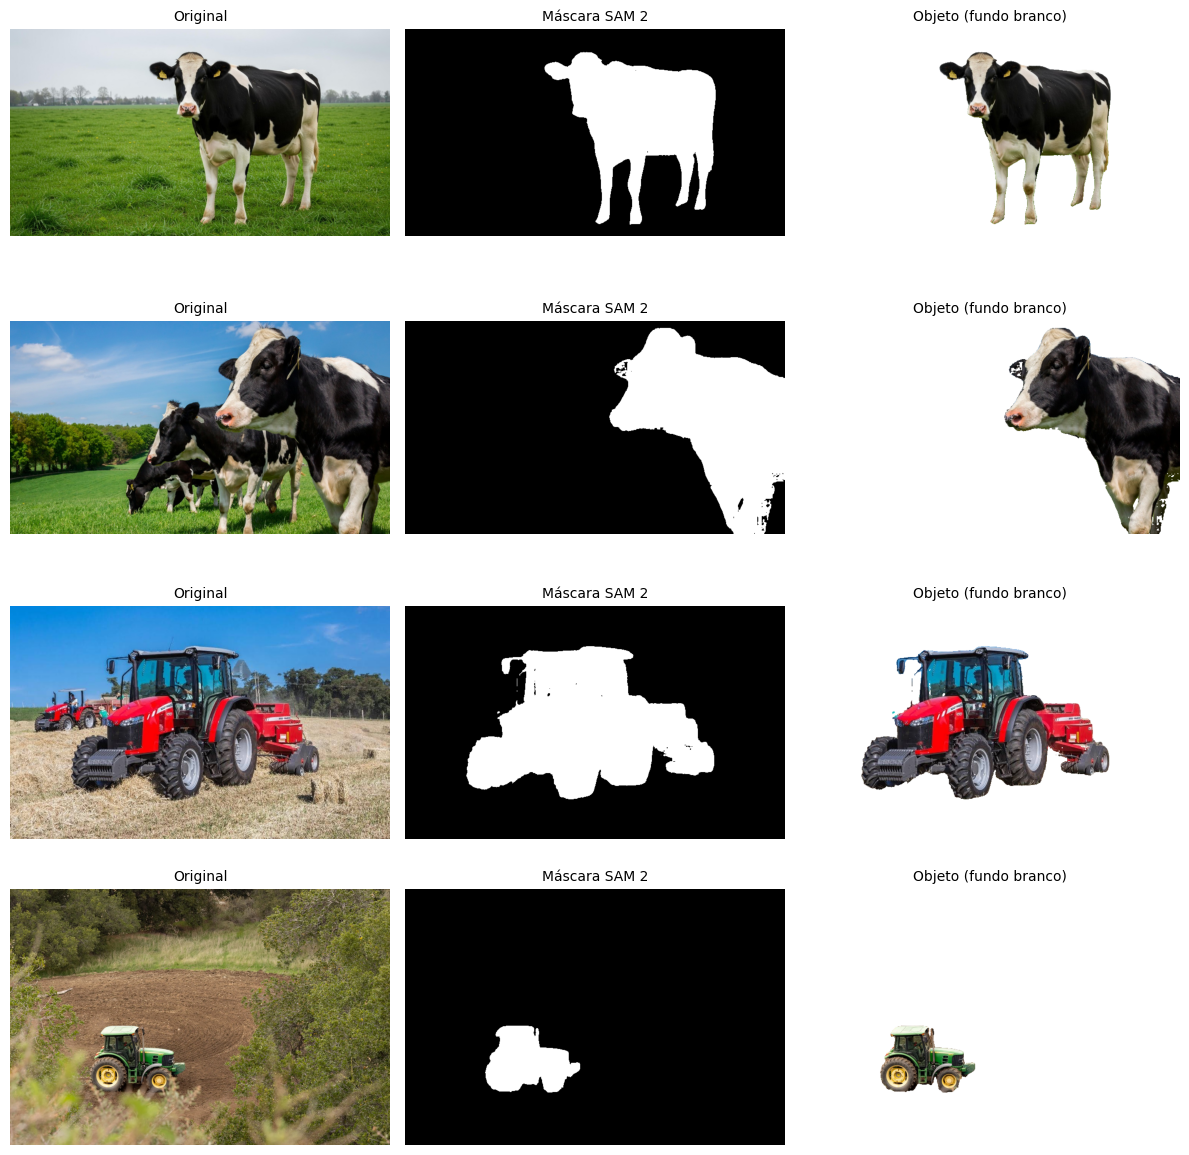

In [5]:
# ── Exemplos: 2 vacas e 2 equipamentos do teste — original, máscara e recorte ──
exemplos = []
for classe in [0, 1]:
    subset = manifest[(manifest.classe_id == classe) & (manifest.split == 'test')]
    exemplos += subset.head(2).to_dict('records')
assert len(exemplos) == 4
fig, axs = plt.subplots(len(exemplos), 3, figsize=(12, 12))
for i, r in enumerate(exemplos):
    origem = np.array(Image.open(r['arquivo_original']).convert('RGB'))
    mascara = np.array(Image.open(LOCAL / 'mascaras' / r['split'] / (r['stem'] + '.png')))
    isolada = np.array(Image.open(LOCAL / 'sem_fundo' / r['split'] / (r['stem'] + '.png')).convert('RGB'))
    info = seg_df[(seg_df.split == r['split']) & (seg_df.stem == r['stem'])].iloc[0]
    for ax, im, titulo in zip(axs[i], [origem, mascara, isolada],
                              ['Original', 'Máscara SAM 2', 'Objeto (fundo branco)']):
        cinza = im.ndim == 2                                        # a máscara é uma imagem de 1 canal
        ax.imshow(im, cmap='gray' if cinza else None, vmin=0 if cinza else None, vmax=255 if cinza else None)
        ax.set_title(titulo, fontsize=10); ax.axis('off')
    axs[i, 0].set_ylabel(f"{r['classe']} | {info.status}", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / 'exemplos_segmentacao.png', dpi=145, bbox_inches='tight')
plt.show()

### 5.1 Leitura das máscaras

- **Contornos:** nas cenas com um objeto bem destacado (vaca isolada no pasto, trator em campo aberto), o SAM 2 acompanha bem a silhueta, incluindo pernas e rodas.
- **Imperfeições visíveis:** em regiões com cor parecida com o fundo ou com bordas finas, a máscara pode apresentar pequenos buracos ou recortes — por exemplo, manchas no dorso da vaca em primeiro plano e partes da cabine envidraçada do trator. Para a classificação isso pouco importa, mas mostra que “máscara válida” não significa “máscara perfeita”.
- **Um objeto por imagem:** por projeto, mantemos só o objeto principal escolhido automaticamente. Em cenas com vários animais ou máquinas, os demais são apagados junto com o fundo; isso muda o conteúdo da imagem e é uma escolha consciente, não um erro da máscara.
- **Dependência da YOLO:** se a caixa da YOLO estiver errada, o SAM 2 segmenta o objeto errado. Por isso registramos, para cada imagem, a classe e a confiança do detector.

## 6. Transfer Learning com MobileNetV2 (ImageNet)

**Escolha da arquitetura:** a MobileNetV2 reaproveita características visuais aprendidas na ImageNet — que inclui vacas, tratores e outros veículos — e é leve o bastante para treinar no Colab T4 e fazer inferências rápidas. Uma VGG16 teria cerca de 6 vezes mais parâmetros na base convolucional (≈14,7 M contra ≈2,3 M), o que aumenta o risco de sobreajuste com apenas 64 exemplos de treino.

**Etapas idênticas nas duas versões (imagem inteira e fundo removido):**

1. **Extração de características:** carregamos a MobileNetV2 com `weights='imagenet'` e `include_top=False`, congelamos toda a base e treinamos apenas um classificador novo (pooling global, *dropout* e uma saída sigmoide), com learning rate **10⁻³**.
2. **Fine Tuning:** liberamos as **30 últimas camadas** da base, exceto as de `BatchNormalization`, e continuamos o treino com learning rate **10⁻⁵** (100 vezes menor).
3. **Pré-processamento:** cada foto é reduzida a **224×224 RGB**, o tamanho em que a rede foi treinada na ImageNet, e passa por `mobilenet_v2.preprocess_input`, que converte os pixels de `[0, 255]` para `[-1, 1]`, a escala esperada pelos pesos pré-treinados. Aumentos de dados (espelhamento, leve rotação e zoom) atuam **somente no treino**.
4. **Avaliação:** *early stopping* pela validação; o **teste não influencia** épocas, hiperparâmetros nem a escolha dos pesos.

**Por que congelar até as 30 últimas camadas?** A MobileNetV2 é organizada em blocos *inverted residual*. Os blocos iniciais aprendem bordas, cores e texturas — úteis para qualquer foto e que não convém alterar com tão poucos exemplos. Os blocos finais combinam esses padrões em partes de objetos mais específicas da ImageNet, e são eles que precisam se adaptar a vacas e máquinas agrícolas. Liberar as 30 últimas camadas alcança apenas os **blocos 14, 15 e 16 e a convolução final (`Conv_1`)** — de 154 camadas, os primeiros 13 blocos continuam congelados (a célula a seguir lista as camadas). Como essas camadas finais são as mais largas da rede, elas concentram cerca de **dois terços dos parâmetros** da base; por isso o Fine Tuning usa um learning rate 100 vezes menor e *early stopping* pela validação, que fazem ajustes finos sem destruir o que foi aprendido nem deixar a rede decorar as 64 fotos. Liberar menos camadas (por exemplo, só o bloco 16) seria uma alternativa mais conservadora; liberar a rede inteira seria arriscado com tão poucos exemplos.

**Por que manter o BatchNormalization congelado?** Essas camadas guardam médias e variâncias calculadas em milhões de imagens da ImageNet. Recalculá-las com lotes de 8 fotos tornaria as estatísticas instáveis. Por isso a base é chamada com `training=False` nas duas fases, conforme a orientação oficial do TensorFlow/Keras.

**Observação honesta:** a acurácia de validação já chegou a 100% na fase 1, com a base congelada. Nesta base pequena, portanto, o ganho do Fine Tuning não é mensurável; ele foi mantido por ser a etapa pedida e porque tende a fazer diferença em bases maiores e mais variadas.

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report, log_loss)

# O TensorFlow não deve reservar toda a memória da GPU
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
keras.utils.set_random_seed(SEED)

# Mesmos exemplos, mesma ordem e mesmas classes nos dois pré-processamentos
ordem = {sp: manifest[manifest.split == sp].reset_index(drop=True) for sp in SPLITS}

def carregar_imagens(split, modo, tamanho):
    """Lê as imagens de uma divisão ('inteira' ou 'sem_fundo') no tamanho pedido."""
    rows = ordem[split]
    diretorio = LOCAL / ('originais' if modo == 'inteira' else 'sem_fundo') / split
    imgs = []
    for r in rows.itertuples():
        with Image.open(diretorio / (r.stem + '.png')) as img:
            imgs.append(np.asarray(img.convert('RGB').resize(tamanho, Image.Resampling.BILINEAR), dtype=np.float32))
    return np.stack(imgs), rows.classe_id.to_numpy(np.int32)

amostras = {}
for modo in ('inteira', 'sem_fundo'):
    amostras[modo] = {split: carregar_imagens(split, modo, SIZE) for split in SPLITS}
    for split in SPLITS:                                           # proteção contra troca de rótulos
        assert np.array_equal(amostras[modo][split][1], ordem[split].classe_id.to_numpy()), 'Classes trocadas!'
print('Tensores treino/val/teste:', [amostras['inteira'][s][0].shape for s in SPLITS])

Tensores treino/val/teste: [(64, 224, 224, 3), (8, 224, 224, 3), (8, 224, 224, 3)]


In [7]:
# ── Quais camadas o Fine Tuning libera? ────────────────────────────────
base_ref = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights=None)  # só a estrutura
total_camadas = len(base_ref.layers)
corte_ref = total_camadas - FINE_LAST_LAYERS
base_ref.trainable = True
for i, camada in enumerate(base_ref.layers):           # mesma regra usada no treino
    camada.trainable = i >= corte_ref and not isinstance(camada, layers.BatchNormalization)
camadas_ft = pd.DataFrame([{'índice': i, 'camada': c.name, 'tipo': type(c).__name__,
                            'no Fine Tuning': 'treinável' if c.trainable else 'congelada (BatchNormalization)'}
                           for i, c in enumerate(base_ref.layers) if i >= corte_ref])
blocos = sorted({'_'.join(n.split('_')[:2]) if n.startswith('block') else n.split('_')[0]
                 for n in camadas_ft.camada})
treinaveis = int(sum(np.prod(w.shape) for w in base_ref.trainable_weights))
total_param = int(base_ref.count_params())
print(f'A base tem {total_camadas} camadas; o Fine Tuning libera as {FINE_LAST_LAYERS} últimas '
      f'(índices {corte_ref} a {total_camadas - 1}), exceto BatchNormalization.')
print('Partes da rede alcançadas:', ', '.join(blocos))
print(f'Parâmetros da base que passam a ser treináveis: {treinaveis:,} de {total_param:,} '
      f'({treinaveis / total_param:.0%}).')
display(camadas_ft)
camadas_ft.to_csv(OUT / 'camadas_fine_tuning.csv', index=False)
del base_ref

A base tem 154 camadas; o Fine Tuning libera as 30 últimas (índices 124 a 153), exceto BatchNormalization.
Partes da rede alcançadas: Conv, block_13, block_14, block_15, block_16, out
Parâmetros da base que passam a ser treináveis: 1,510,720 de 2,257,984 (67%).


,índice,camada,tipo,no Fine Tuning
0,124,block_13_project_BN,BatchNormalization,congelada (BatchNormalization)
1,125,block_14_expand,Conv2D,treinável
2,126,block_14_expand_BN,BatchNormalization,congelada (BatchNormalization)
3,127,block_14_expand_relu,ReLU,treinável
4,128,block_14_depthwise,DepthwiseConv2D,treinável
5,129,block_14_depthwise_BN,BatchNormalization,congelada (BatchNormalization)
6,130,block_14_depthwise_relu,ReLU,treinável
7,131,block_14_project,Conv2D,treinável
8,132,block_14_project_BN,BatchNormalization,congelada (BatchNormalization)
9,133,block_14_add,Add,treinável


In [8]:
def construir_mobilenet():
    """MobileNetV2 ImageNet congelada + classificador binário novo."""
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base.trainable = False                                       # fase 1: base inteira congelada
    aug = keras.Sequential([
        layers.RandomFlip('horizontal'), layers.RandomRotation(0.05),
        layers.RandomZoom(0.10)], name='augmentacao_treino')    # ativo só durante o treino
    inp = keras.Input(shape=(224, 224, 3))
    x = aug(inp)
    x = keras.applications.mobilenet_v2.preprocess_input(x)      # pixels [0,255] → [-1,1]
    x = base(x, training=False)                                  # BatchNormalization em modo inferência
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(1, activation='sigmoid')(x)             # probabilidade de equipamento_pesado
    return keras.Model(inp, saida), base

def compilar(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=[keras.metrics.BinaryAccuracy(name='accuracy')])

def callback_fase():
    """Early stopping pela validação e redução do learning rate em platôs."""
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5, min_lr=1e-7)]

def treinar_variante(modo):
    """Treina (ou reaproveita) a MobileNetV2 para 'inteira' ou 'sem_fundo'."""
    pasta = OUT / 'modelos' / modo
    pasta.mkdir(parents=True, exist_ok=True)
    checkpoint = pasta / 'modelo_final.keras'
    caminho_metricas = pasta / 'historico.csv'
    if checkpoint.exists() and caminho_metricas.exists() and not REFAZER_TREINOS:
        print(f'Modelo encontrado para {modo}: reaproveitando o checkpoint.')
        return (keras.models.load_model(checkpoint), pd.read_csv(caminho_metricas),
                float((pasta / 'tempo_treino_segundos.txt').read_text()))
    keras.utils.set_random_seed(SEED)                            # mesmo estado inicial nas duas variantes
    modelo, base = construir_mobilenet()
    Xtr, ytr = amostras[modo]['train']; Xv, yv = amostras[modo]['val']
    t0 = time.perf_counter()
    # Fase 1 — só o classificador novo aprende
    compilar(modelo, 1e-3)
    h1 = modelo.fit(Xtr, ytr, validation_data=(Xv, yv), epochs=EPOCHS_CABECALHO,
                    batch_size=BATCH_SIZE, callbacks=callback_fase(), verbose=2)
    # Fase 2 — Fine Tuning das últimas 30 camadas (exceto BatchNormalization)
    base.trainable = True
    corte = max(0, len(base.layers) - FINE_LAST_LAYERS)
    for i, layer in enumerate(base.layers):
        layer.trainable = (i >= corte and not isinstance(layer, layers.BatchNormalization))
    assert any(layer.trainable for layer in base.layers)
    compilar(modelo, 1e-5)                                       # recompilar após mudar trainable
    h2 = modelo.fit(Xtr, ytr, validation_data=(Xv, yv), epochs=EPOCHS_FINE,
                    batch_size=BATCH_SIZE, callbacks=callback_fase(), verbose=2)
    duracao = time.perf_counter() - t0
    historico = pd.concat([pd.DataFrame(h1.history).assign(fase='transfer_learning'),
                           pd.DataFrame(h2.history).assign(fase='fine_tuning')], ignore_index=True)
    modelo.save(checkpoint)
    historico.to_csv(caminho_metricas, index=False)
    (pasta / 'tempo_treino_segundos.txt').write_text(f'{duracao:.3f}')
    (pasta / 'config.json').write_text(json.dumps({
        'arquitetura': 'MobileNetV2 ImageNet', 'camadas_finais_descongeladas': FINE_LAST_LAYERS,
        'BatchNormalization': 'congelada', 'lr_head': 1e-3, 'lr_fine': 1e-5,
        'max_epochs_head': EPOCHS_CABECALHO, 'max_epochs_fine': EPOCHS_FINE,
        'epocas_executadas': len(historico), 'seed': SEED}, indent=2))
    return modelo, historico, duracao

print('Primeira variante: imagens inteiras.')
modelo_inteira, hist_inteira, tempo_inteira = treinar_variante('inteira')

Primeira variante: imagens inteiras.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
8/8 - 9s - 1s/step - accuracy: 0.8594 - loss: 0.4007 - val_accuracy: 0.8750 - val_loss: 0.2350 - learning_rate: 0.0010
Epoch 2/15
8/8 - 0s - 45ms/step - accuracy: 0.9062 - loss: 0.2669 - val_accuracy: 1.0000 - val_loss: 0.1120 - learning_rate: 0.0010
Epoch 3/15
8/8 - 0s - 42ms/step - accuracy: 0.9844 - loss: 0.1254 - val_accuracy: 1.0000 - val_loss: 0.0616 - learning_rate: 0.0010
Epoch 4/15
8/8 - 0s - 42ms/step - accuracy: 1.0000 - loss: 0.0799 - val_accuracy: 1.0000 - val_loss: 0.0412 - learning_rate: 0.0010
Epoch 5/15
8/8 - 0s - 46ms/step - accuracy: 0.9844 - loss: 0.0645 - val_accuracy: 1.0000 - val_loss: 0.0324 - learning_rate: 0.0010
Epoch 6/15
8/8 - 0s - 41ms/step - accuracy: 1.0000 - loss: 0.0443 - val_accuracy: 1.0000 - val_loss: 0.0268 - learning_rate: 0.0010
Epoch 7/15
8/8 - 0s - 45ms/step - accuracy: 1.0000 - loss: 0.0415 - val_accuracy: 1.0000 - val_loss: 0.0230 - learning_rate:

In [9]:
print('Segunda variante: máscaras automáticas e fundo branco.')
# Mesma arquitetura e mesmos hiperparâmetros; só muda a imagem de entrada
modelo_mask, hist_mask, tempo_mask = treinar_variante('sem_fundo')

Segunda variante: máscaras automáticas e fundo branco.
Epoch 1/15
8/8 - 6s - 727ms/step - accuracy: 0.7500 - loss: 0.5379 - val_accuracy: 1.0000 - val_loss: 0.2661 - learning_rate: 0.0010
Epoch 2/15
8/8 - 0s - 47ms/step - accuracy: 0.9531 - loss: 0.2577 - val_accuracy: 1.0000 - val_loss: 0.1199 - learning_rate: 0.0010
Epoch 3/15
8/8 - 0s - 43ms/step - accuracy: 0.9844 - loss: 0.1213 - val_accuracy: 1.0000 - val_loss: 0.0747 - learning_rate: 0.0010
Epoch 4/15
8/8 - 0s - 43ms/step - accuracy: 0.9844 - loss: 0.1198 - val_accuracy: 1.0000 - val_loss: 0.0496 - learning_rate: 0.0010
Epoch 5/15
8/8 - 0s - 49ms/step - accuracy: 0.9844 - loss: 0.0703 - val_accuracy: 1.0000 - val_loss: 0.0359 - learning_rate: 0.0010
Epoch 6/15
8/8 - 0s - 44ms/step - accuracy: 0.9844 - loss: 0.0729 - val_accuracy: 1.0000 - val_loss: 0.0275 - learning_rate: 0.0010
Epoch 7/15
8/8 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0520 - val_accuracy: 1.0000 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 8/15
8/8 - 0s 

## 7. Métricas, gráficos e comparação pareada (teste intocado)

Calculamos **acurácia, F1 macro, *balanced accuracy*, matriz de confusão e tempo de inferência**. O F1 macro dá o mesmo peso às duas classes.

Como existem apenas **8 imagens de teste**, uma única resposta errada altera a acurácia em **12,5 pontos percentuais**. Diferenças devem ser descritas como indício, não como prova. A comparação pareada por imagem mostra quais casos melhoraram ou pioraram.

**Tempo de inferência:** as duas MobileNetV2 são executadas em modo grafo (`tf.function`), forma usada em produção, depois de um aquecimento das duas; as medições alternam a ordem dos modelos e usam a mediana. O tempo **total** da abordagem segmentada soma a localização YOLO, a máscara SAM 2 (mediana por imagem) e a classificação.

**Uma observação importante:** registramos também a classe que a **própria YOLO** atribuiu ao objeto escolhido. Se ela já acerta as imagens de teste, o primeiro estágio do pipeline segmentado já resolve a classificação sozinho — e o classificador depois da máscara passa a ser redundante para esta base.

In [10]:
# ── Avaliação idêntica nas duas variantes, sem ajustar limiar pelo teste ──
from scipy.stats import binomtest

def medir_inferencia(modelos_tf, entradas, rodadas=7):
    """Mediana de ms/imagem em modo grafo, com aquecimento global e ordem alternada."""
    def grafo(mod):
        @tf.function
        def f(x):
            return mod(x, training=False)                         # modo grafo, sem augmentations
        return f
    fns = {m: grafo(mod) for m, mod in modelos_tf.items()}
    for m, fn in fns.items():                                     # aquecimento (inclui compilar o grafo)
        for a in entradas[m][:3]:
            fn(a[None]).numpy()
    tempos = {m: [] for m in fns}
    sequencia = list(fns)
    for r in range(rodadas):
        for m in (sequencia if r % 2 == 0 else sequencia[::-1]):
            t0 = time.perf_counter()
            for a in entradas[m]:
                fns[m](a[None]).numpy()                           # .numpy() espera a GPU terminar
            tempos[m].append(1000 * (time.perf_counter() - t0) / len(entradas[m]))
    return {m: float(np.median(v)) for m, v in tempos.items()}

modelos = {'inteira': modelo_inteira, 'sem_fundo': modelo_mask}
historicos = {'inteira': hist_inteira, 'sem_fundo': hist_mask}
tempos = {'inteira': tempo_inteira, 'sem_fundo': tempo_mask}
y_real = amostras['inteira']['test'][1]
latencias = medir_inferencia(modelos, {m: amostras[m]['test'][0] for m in modelos})

metricas = []; predicts = {}; probas = {}
for modo, modelo in modelos.items():
    X, y = amostras[modo]['test']
    assert np.array_equal(y, y_real)
    probabilidades = modelo.predict(X, verbose=0).ravel()
    pred = (probabilidades >= 0.5).astype(int)                     # limiar fixo de 0,5
    predicts[modo] = pred; probas[modo] = probabilidades
    metricas.append({'abordagem': modo, 'acuracia_teste': accuracy_score(y, pred),
                     'f1_macro': f1_score(y, pred, average='macro', zero_division=0),
                     'balanced_accuracy': balanced_accuracy_score(y, pred),
                     'loss_teste': log_loss(y, probabilidades, labels=[0, 1]),
                     'acertos': int((y == pred).sum()), 'erros': int((y != pred).sum()),
                     'tempo_treino_min': tempos[modo] / 60,
                     'inferencia_rede_ms_por_imagem': latencias[modo]})
    print('\n===', modo, '===')
    print(classification_report(y, pred, labels=[0, 1], target_names=CLASSES, zero_division=0))

resumo = pd.DataFrame(metricas)
ms_segmentacao = float(seg_df.ms_detector_e_segmentador.median())   # mediana: menos sensível a picos
resumo['segmentacao_ms_por_imagem'] = [0.0, ms_segmentacao]
resumo['pipeline_ms_por_imagem'] = resumo['inferencia_rede_ms_por_imagem'] + resumo['segmentacao_ms_por_imagem']
resumo.to_csv(OUT / 'metricas_ir_alem.csv', index=False)
display(resumo.round(3))

# Comparação imagem a imagem
comparacao = ordem['test'][['stem', 'classe', 'classe_id']].copy()
for modo in modelos:
    comparacao[f'prev_{modo}'] = [CLASSES[c] for c in predicts[modo]]
    comparacao[f'acerto_{modo}'] = predicts[modo] == y_real
    comparacao[f'prob_equipamento_{modo}'] = probas[modo]
comparacao = comparacao.merge(seg_df[['split', 'stem', 'status', 'classe_detector', 'conf_detector']],
                              on='stem', how='left', validate='one_to_one')
comparacao['acerto_yolo_sozinha'] = comparacao.classe_detector == comparacao.classe_id
acc_detector = float(comparacao.acerto_yolo_sozinha.mean())        # a YOLO como classificador
comparacao.to_csv(OUT / 'comparacao_pareada_teste.csv', index=False)
display(comparacao.drop(columns=['classe_id']))

n_melhora = int(((predicts['inteira'] != y_real) & (predicts['sem_fundo'] == y_real)).sum())
n_piora = int(((predicts['inteira'] == y_real) & (predicts['sem_fundo'] != y_real)).sum())
p_exato = binomtest(n_melhora, n_melhora + n_piora, 0.5).pvalue if n_melhora + n_piora else 1.0
print(f'Imagens corrigidas pela máscara: {n_melhora}; prejudicadas: {n_piora}; teste pareado exato: p={p_exato:.3f}')
print(f'Classe da própria YOLO (objeto principal) correta em {comparacao.acerto_yolo_sozinha.sum()}/8 imagens de teste.')


=== inteira ===
                    precision    recall  f1-score   support

              vaca       1.00      1.00      1.00         4
equipamento_pesado       1.00      1.00      1.00         4

          accuracy                           1.00         8
         macro avg       1.00      1.00      1.00         8
      weighted avg       1.00      1.00      1.00         8


=== sem_fundo ===
                    precision    recall  f1-score   support

              vaca       1.00      1.00      1.00         4
equipamento_pesado       1.00      1.00      1.00         4

          accuracy                           1.00         8
         macro avg       1.00      1.00      1.00         8
      weighted avg       1.00      1.00      1.00         8



,abordagem,acuracia_teste,f1_macro,balanced_accuracy,loss_teste,...,erros,tempo_treino_min,inferencia_rede_ms_por_imagem,segmentacao_ms_por_imagem,pipeline_ms_por_imagem
0,inteira,1.0,1.0,1.0,0.001,...,0,0.441,6.054,0.000,6.054
1,sem_fundo,1.0,1.0,1.0,0.003,...,0,0.337,5.805,144.411,150.217


,stem,classe,prev_inteira,acerto_inteira,prob_equipamento_inteira,...,split,status,classe_detector,conf_detector,acerto_yolo_sozinha
0,71060961-vaca-em-pe-dentro-verde-pasto-gado-ag...,vaca,vaca,True,0.000125,...,test,ok,0,0.863416,True
1,8e658346-5a86-4f20-a876-557e24a75e31,equipamento_pesado,equipamento_pesado,True,0.999877,...,test,ok,1,0.801508,True
2,WhatsApp-Image-2020-06-23-at-11.19.49,vaca,vaca,True,0.001509,...,test,ok,0,0.785015,True
3,pexels-christina99999-34582680,vaca,vaca,True,0.000352,...,test,ok,0,0.808301,True
4,pexels-malama-mushitu-2148898721-34198067,vaca,vaca,True,0.000132,...,test,ok,0,0.721220,True
5,pexels-ninobur-14911318,equipamento_pesado,equipamento_pesado,True,0.994332,...,test,ok,1,0.791861,True
6,pexels-stokeron-27135349,equipamento_pesado,equipamento_pesado,True,0.999809,...,test,ok,1,0.698245,True
7,pexels-tomfisk-28840174,equipamento_pesado,equipamento_pesado,True,0.999834,...,test,ok,1,0.710351,True


Imagens corrigidas pela máscara: 0; prejudicadas: 0; teste pareado exato: p=1.000
Classe da própria YOLO (objeto principal) correta em 8/8 imagens de teste.


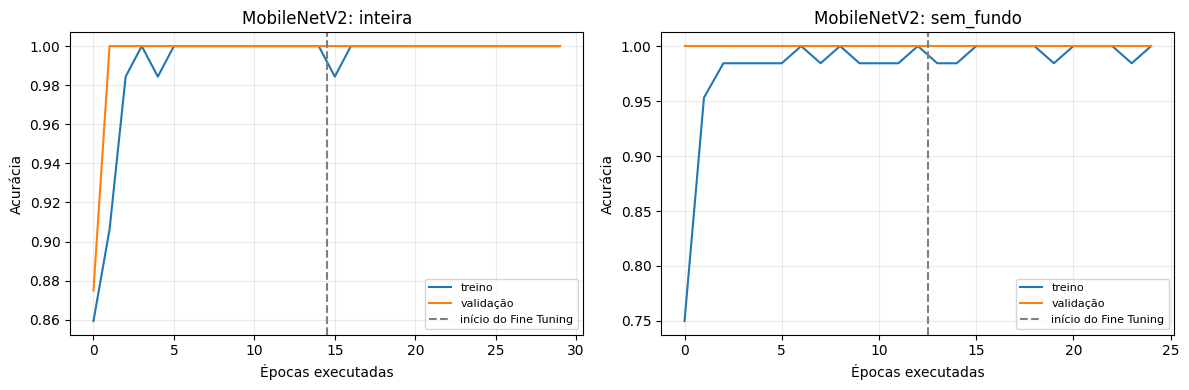

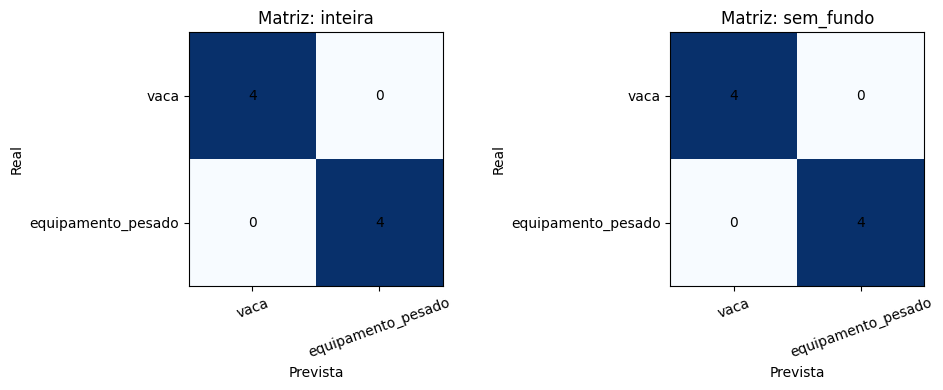

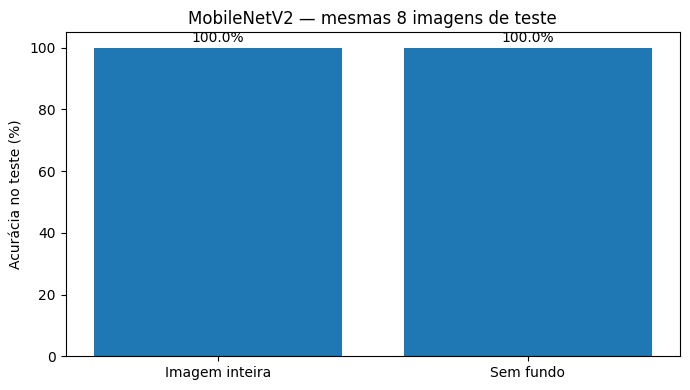

In [11]:
# ── Figuras exportáveis para o GitHub e o vídeo ─────────────────────────
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (modo, hist) in zip(axs, historicos.items()):
    ax.plot(hist['accuracy'].to_numpy(), label='treino')
    ax.plot(hist['val_accuracy'].to_numpy(), label='validação')
    ax.axvline((hist.fase == 'transfer_learning').sum() - 0.5, linestyle='--', color='grey',
               label='início do Fine Tuning')
    ax.set_title('MobileNetV2: ' + modo); ax.set_xlabel('Épocas executadas')
    ax.set_ylabel('Acurácia'); ax.legend(fontsize=8); ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig(OUT / 'curvas_transfer_learning.png', dpi=150, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, modo in zip(axs, ['inteira', 'sem_fundo']):
    matriz = confusion_matrix(y_real, predicts[modo], labels=[0, 1])
    ax.imshow(matriz, cmap='Blues', vmin=0, vmax=4)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matriz[i, j]), ha='center', va='center')
    ax.set_xticks([0, 1], CLASSES, rotation=20); ax.set_yticks([0, 1], CLASSES)
    ax.set_xlabel('Prevista'); ax.set_ylabel('Real'); ax.set_title('Matriz: ' + modo)
plt.tight_layout()
plt.savefig(OUT / 'matrizes_confusao_ir_alem.png', dpi=150, bbox_inches='tight'); plt.show()

plt.figure(figsize=(7, 4))
plt.bar(['Imagem inteira', 'Sem fundo'], resumo.acuracia_teste * 100)
plt.ylim(0, 105); plt.ylabel('Acurácia no teste (%)')
for i, valor in enumerate(resumo.acuracia_teste):
    plt.text(i, valor * 100 + 2, f'{valor:.1%}', ha='center')
plt.title('MobileNetV2 — mesmas 8 imagens de teste')
plt.tight_layout(); plt.savefig(OUT / 'comparacao_acuracia.png', dpi=150); plt.show()

## 7.1 Hipótese 2 com margem para medir: CNN do zero com e sem fundo

As duas MobileNetV2 acertaram **8/8**: há **efeito teto**, e nenhuma diferença poderia aparecer. Para testar a hipótese da segmentação de forma informativa, repetimos a comparação com a **CNN do zero** — o classificador que mais errou na Entrega 2 e que, segundo a nossa interpretação, se apoiava no fundo da imagem.

**Desenho do experimento:**
- mesma arquitetura, entrada (150×150), *augmentations*, otimizador e *early stopping* da Entrega 2;
- duas versões de entrada: **imagem inteira** e **fundo removido**, com as mesmas imagens e a mesma divisão;
- **5 sementes** por versão; em cada semente, as duas versões partem da **mesma inicialização**, o que permite comparação pareada;
- relatamos média, desvio padrão e, imagem a imagem, quantas vezes a máscara corrigiu ou causou erros (teste pareado exato, exploratório).

A CNN “inteira” daqui não é idêntica à da Entrega 2 (aqui as fotos passam pela redução para 768 px usada na segmentação, e há 5 repetições em vez de uma). Ela é o **controle** desta comparação.

semente   42 | inteira   | teste 3/8 | 60 épocas
semente   42 | sem_fundo | teste 3/8 | 22 épocas


semente    7 | inteira   | teste 4/8 | 38 épocas


semente    7 | sem_fundo | teste 3/8 | 20 épocas
semente  123 | inteira   | teste 4/8 | 30 épocas
semente  123 | sem_fundo | teste 3/8 | 25 épocas
semente 2024 | inteira   | teste 3/8 | 51 épocas
semente 2024 | sem_fundo | teste 5/8 | 56 épocas
semente   99 | inteira   | teste 3/8 | 36 épocas
semente   99 | sem_fundo | teste 3/8 | 22 épocas


,acuracia_media,desvio,minimo,maximo,acertos_totais
modo,,,,,
inteira,0.425,0.068,0.375,0.500,17
sem_fundo,0.425,0.112,0.375,0.625,17


modo,inteira,sem_fundo,diferenca_sem_fundo_menos_inteira
semente,,,
7,4,3,-1
42,3,3,0
99,3,3,0
123,4,3,-1
2024,3,5,2


Pares imagem×semente corrigidos pela máscara: 7; prejudicados: 7; teste pareado exato: p=1.000


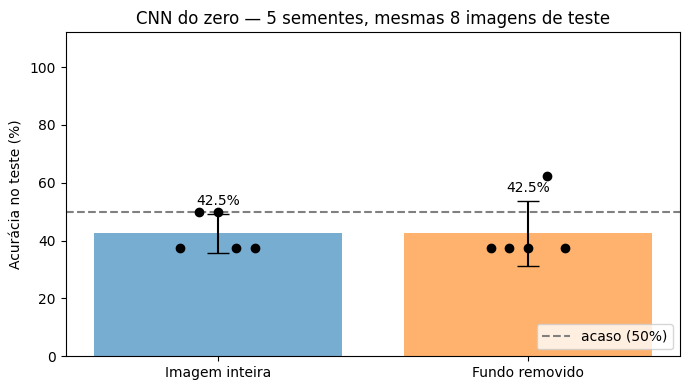

In [12]:
# ── CNN do zero: imagem inteira × fundo removido, 5 sementes cada ──────
def construir_cnn_zero():
    """Mesma arquitetura da CNN da Entrega 2 (seção 8 do notebook principal)."""
    aug = keras.Sequential([layers.RandomFlip('horizontal'), layers.RandomRotation(.08),
                            layers.RandomZoom(.15), layers.RandomContrast(.15)], name='augmentation')
    return keras.Sequential([
        layers.Input(shape=(*CNN_SIZE, 3)), aug, layers.Rescaling(1/255.),
        layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(), layers.Dropout(.3),
        layers.Dense(32, activation='relu'), layers.Dense(1, activation='sigmoid')])

csv_cnn = OUT / 'cnn_zero_sementes.csv'
if csv_cnn.exists() and not REFAZER_CNN:
    cnn_runs = pd.read_csv(csv_cnn, dtype={'predicoes': str})
    print('Rodadas da CNN do zero reaproveitadas do Drive.')
else:
    dados_cnn = {modo: {sp: carregar_imagens(sp, modo, CNN_SIZE) for sp in SPLITS}
                 for modo in ('inteira', 'sem_fundo')}
    registros = []
    for semente in SEMENTES_CNN:
        for modo in ('inteira', 'sem_fundo'):
            keras.backend.clear_session()
            keras.utils.set_random_seed(semente)                 # mesma inicialização nas duas versões
            rede = construir_cnn_zero()
            rede.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
            (Xtr, ytr), (Xv, yv), (Xte, yte) = (dados_cnn[modo][s] for s in ('train', 'val', 'test'))
            t0 = time.perf_counter()
            h = rede.fit(Xtr, ytr, validation_data=(Xv, yv), epochs=100, batch_size=8, verbose=0,
                         callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=12,
                                                                  restore_best_weights=True),
                                    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=5)])
            duracao = time.perf_counter() - t0
            pred = (rede.predict(Xte, verbose=0).ravel() >= .5).astype(int)
            registros.append({'semente': semente, 'modo': modo, 'acertos': int((pred == yte).sum()),
                              'acuracia_teste': float((pred == yte).mean()),
                              'acuracia_val': float(rede.evaluate(Xv, yv, verbose=0)[1]),
                              'epocas': len(h.history['loss']), 'tempo_s': round(duracao, 1),
                              'predicoes': ''.join(map(str, pred))})
            print(f'semente {semente:>4} | {modo:9s} | teste {registros[-1]["acertos"]}/8 | '
                  f'{registros[-1]["epocas"]} épocas')
    cnn_runs = pd.DataFrame(registros)
    cnn_runs.to_csv(csv_cnn, index=False)
    del dados_cnn; gc.collect()

# Resumo por versão
resumo_cnn = cnn_runs.groupby('modo').agg(acuracia_media=('acuracia_teste', 'mean'),
                                          desvio=('acuracia_teste', 'std'),
                                          minimo=('acuracia_teste', 'min'), maximo=('acuracia_teste', 'max'),
                                          acertos_totais=('acertos', 'sum'))
display(resumo_cnn.round(3))

# Comparação pareada por semente e por imagem (sementes × 8 imagens)
pares = cnn_runs.pivot(index='semente', columns='modo', values='acertos')
pares['diferenca_sem_fundo_menos_inteira'] = pares['sem_fundo'] - pares['inteira']
display(pares)
acerto_por_imagem = {m: np.array([[int(c) == y for c, y in zip(p, y_real)]
                                  for p in cnn_runs[cnn_runs.modo == m].sort_values('semente').predicoes])
                     for m in ('inteira', 'sem_fundo')}
cnn_melhora = int((~acerto_por_imagem['inteira'] & acerto_por_imagem['sem_fundo']).sum())
cnn_piora = int((acerto_por_imagem['inteira'] & ~acerto_por_imagem['sem_fundo']).sum())
p_cnn = binomtest(cnn_melhora, cnn_melhora + cnn_piora, 0.5).pvalue if cnn_melhora + cnn_piora else 1.0
print(f'Pares imagem×semente corrigidos pela máscara: {cnn_melhora}; prejudicados: {cnn_piora}; '
      f'teste pareado exato: p={p_cnn:.3f}')

# Gráfico: média ± desvio e cada semente como ponto
fig, ax = plt.subplots(figsize=(7, 4))
rotulos = {'inteira': 'Imagem inteira', 'sem_fundo': 'Fundo removido'}
for i, modo in enumerate(['inteira', 'sem_fundo']):
    valores = cnn_runs[cnn_runs.modo == modo].acuracia_teste * 100
    ax.bar(i, valores.mean(), yerr=valores.std(), capsize=8, alpha=.6)
    ax.scatter(np.full(len(valores), i) + np.linspace(-.12, .12, len(valores)), valores, color='black', zorder=3)
    ax.text(i, min(valores.mean() + valores.std(), 100) + 3, f'{valores.mean():.1f}%', ha='center')
ax.axhline(50, linestyle='--', color='grey', label='acaso (50%)')
ax.set_xticks([0, 1], [rotulos['inteira'], rotulos['sem_fundo']])
ax.set_ylim(0, 112); ax.set_ylabel('Acurácia no teste (%)'); ax.legend(loc='lower right')
ax.set_title(f'CNN do zero — {len(SEMENTES_CNN)} sementes, mesmas 8 imagens de teste')
plt.tight_layout(); plt.savefig(OUT / 'cnn_zero_com_sem_fundo.png', dpi=150); plt.show()

## 8. Hipóteses respondidas com os resultados

O código abaixo escreve a interpretação a partir das métricas calculadas nesta execução, para que texto e números não se separem.

A acurácia da CNN do zero da **Entrega 2** é lida do arquivo de métricas do notebook principal, quando presente no Drive. Ela vem de outro treino e serve como referência descritiva; o controle direto da hipótese 2 é a seção 7.1.

In [13]:
base = resumo.set_index('abordagem')
ai = float(base.loc['inteira', 'acuracia_teste'])
am = float(base.loc['sem_fundo', 'acuracia_teste'])
delta = am - ai
falhas = int((seg_df.status != 'ok').sum())
falhas_teste = int(((seg_df.status != 'ok') & (seg_df.split == 'test')).sum())

# CNN do zero da Entrega 2 (referência descritiva)
json_cnn = ROOT / 'resultados_revisao/cnn/metricas.json'
referencia = 'O arquivo de métricas da CNN da Entrega 2 não foi encontrado; consulte a seção 8 do notebook principal.'
if json_cnn.exists():
    dados_ref = json.loads(json_cnn.read_text(encoding='utf-8'))
    if 'acuracia_teste' in dados_ref:
        referencia = (f"A CNN do zero da Entrega 2 obteve {dados_ref['acuracia_teste']:.1%} no mesmo teste, "
                      f"e a média das 5 sementes da CNN do zero com imagem inteira (seção 7.1) foi "
                      f"{resumo_cnn.loc['inteira', 'acuracia_media']:.1%}.")

# Leitura da hipótese 2 com a MobileNetV2
if ai == 1.0 and am == 1.0:
    parecer_mobilenet = ('As duas versões acertaram 8/8: há **efeito teto**, e esta comparação é **inconclusiva** — '
                         'não mostra que a segmentação ajuda, nem que atrapalha.')
elif delta > 0:
    parecer_mobilenet = 'A remoção do fundo MELHOROU a acurácia observada da MobileNetV2.'
elif delta < 0:
    parecer_mobilenet = 'A remoção do fundo PIOROU a acurácia observada da MobileNetV2.'
else:
    parecer_mobilenet = 'A remoção do fundo NÃO ALTEROU a acurácia observada da MobileNetV2.'

# Leitura da hipótese 2 com a CNN do zero (5 sementes)
mi = float(resumo_cnn.loc['inteira', 'acuracia_media']); ms_ = float(resumo_cnn.loc['sem_fundo', 'acuracia_media'])
dif_cnn = ms_ - mi
if dif_cnn > 0 and p_cnn < 0.05:
    parecer_cnn = ('a remoção do fundo **melhorou de forma consistente** a CNN do zero, o que **sustenta a hipótese 2** '
                   'para um modelo sem pré-treinamento: tirar o cenário ajudou a rede a olhar para o objeto.')
elif dif_cnn > 0:
    parecer_cnn = ('a remoção do fundo **melhorou a média** da CNN do zero, mas a diferença ainda não é estatisticamente '
                   'robusta com este volume de dados — é um **indício favorável** à hipótese 2, não uma prova.')
elif dif_cnn < 0 and p_cnn < 0.05:
    parecer_cnn = ('a remoção do fundo **piorou de forma consistente** a CNN do zero: nesta base, o contexto '
                   '(pasto, lavoura) parece carregar informação útil, e a hipótese 2 **não se sustenta**.')
elif dif_cnn < 0:
    parecer_cnn = ('a remoção do fundo **reduziu a média** da CNN do zero, sem diferença estatisticamente robusta; '
                   'os dados **não sustentam** a hipótese 2 nesta base.')
else:
    parecer_cnn = 'a remoção do fundo **não alterou** a média da CNN do zero; os dados não sustentam a hipótese 2.'

texto = f"""# Conclusões — Ir Além (resultados desta execução)

**Hipótese 1 — Transfer Learning:** a MobileNetV2 pré-treinada na ImageNet, com Fine Tuning das últimas {FINE_LAST_LAYERS} camadas (BatchNormalization congelada), alcançou **{ai:.1%}** nas 8 imagens de teste com imagens inteiras. {referencia} O resultado é compatível com o benefício do pré-treinamento, mas as redes diferem também em arquitetura e resolução, e a amostra é pequena; não é uma prova causal isolada.

**Hipótese 2 — Segmentação, com a MobileNetV2:** a versão com fundo removido alcançou **{am:.1%}** (diferença de {delta:+.1%}). {parecer_mobilenet} Imagens corrigidas pela máscara: {n_melhora}; prejudicadas: {n_piora}.

**Hipótese 2 — Segmentação, com a CNN do zero ({len(SEMENTES_CNN)} sementes):** média de **{mi:.1%} ± {resumo_cnn.loc['inteira', 'desvio']:.1%}** com imagem inteira e **{ms_:.1%} ± {resumo_cnn.loc['sem_fundo', 'desvio']:.1%}** com fundo removido (diferença de {dif_cnn:+.1%}). Nos {len(SEMENTES_CNN) * 8} pares imagem × semente, a máscara corrigiu {cnn_melhora} e prejudicou {cnn_piora} (teste pareado exato p={p_cnn:.3f}, exploratório). Conclusão: {parecer_cnn}

**A própria YOLO como classificador:** a classe atribuída pela YOLO ao objeto principal acertou **{comparacao.acerto_yolo_sozinha.sum()}/8** imagens de teste ({acc_detector:.0%}). Ou seja, no pipeline segmentado o primeiro estágio já carrega a informação de classe; para esta base, o classificador após a máscara acrescenta pouco além de uma segunda opinião.

**Qualidade da segmentação:** {falhas} casos sem máscara válida entre 80 imagens ({falhas_teste} no teste). Máscara válida não significa contorno perfeito (seção 5.1).

**Custo computacional:** mediana de **{ms_segmentacao:.1f} ms por imagem** para localizar (YOLO) e segmentar (SAM 2), além da classificação. Pipeline total: **{base.loc['inteira', 'pipeline_ms_por_imagem']:.1f} ms** (imagem inteira) contra **{base.loc['sem_fundo', 'pipeline_ms_por_imagem']:.1f} ms** (fundo removido) por imagem na GPU desta execução. Treino das MobileNetV2: {tempo_inteira/60:.2f} e {tempo_mask/60:.2f} min (sem incluir a geração das máscaras).

**Limitações:** conjunto muito pequeno, rótulos de detecção parcialmente completos, segmentação dependente de uma YOLO treinada no domínio, escolha automática de um único objeto e tempos dependentes da GPU. São conclusões de uma prova de conceito acadêmica.

**Decisão para o cliente fictício:** para classificação, usar a **MobileNetV2 com a imagem inteira** — mesma acurácia observada, menos componentes e menor custo. Reavaliar a segmentação quando houver mais dados e cenas mais difíceis.
"""
_ = (OUT / 'conclusoes_ir_alem.md').write_text(texto, encoding='utf-8')
display(Markdown(texto))

# Conclusões — Ir Além (resultados desta execução)

**Hipótese 1 — Transfer Learning:** a MobileNetV2 pré-treinada na ImageNet, com Fine Tuning das últimas 30 camadas (BatchNormalization congelada), alcançou **100.0%** nas 8 imagens de teste com imagens inteiras. A CNN do zero da Entrega 2 obteve 37.5% no mesmo teste, e a média das 5 sementes da CNN do zero com imagem inteira (seção 7.1) foi 42.5%. O resultado é compatível com o benefício do pré-treinamento, mas as redes diferem também em arquitetura e resolução, e a amostra é pequena; não é uma prova causal isolada.

**Hipótese 2 — Segmentação, com a MobileNetV2:** a versão com fundo removido alcançou **100.0%** (diferença de +0.0%). As duas versões acertaram 8/8: há **efeito teto**, e esta comparação é **inconclusiva** — não mostra que a segmentação ajuda, nem que atrapalha. Imagens corrigidas pela máscara: 0; prejudicadas: 0.

**Hipótese 2 — Segmentação, com a CNN do zero (5 sementes):** média de **42.5% ± 6.8%** com imagem inteira e **42.5% ± 11.2%** com fundo removido (diferença de +0.0%). Nos 40 pares imagem × semente, a máscara corrigiu 7 e prejudicou 7 (teste pareado exato p=1.000, exploratório). Conclusão: a remoção do fundo **não alterou** a média da CNN do zero; os dados não sustentam a hipótese 2.

**A própria YOLO como classificador:** a classe atribuída pela YOLO ao objeto principal acertou **8/8** imagens de teste (100%). Ou seja, no pipeline segmentado o primeiro estágio já carrega a informação de classe; para esta base, o classificador após a máscara acrescenta pouco além de uma segunda opinião.

**Qualidade da segmentação:** 0 casos sem máscara válida entre 80 imagens (0 no teste). Máscara válida não significa contorno perfeito (seção 5.1).

**Custo computacional:** mediana de **144.4 ms por imagem** para localizar (YOLO) e segmentar (SAM 2), além da classificação. Pipeline total: **6.1 ms** (imagem inteira) contra **150.2 ms** (fundo removido) por imagem na GPU desta execução. Treino das MobileNetV2: 0.44 e 0.34 min (sem incluir a geração das máscaras).

**Limitações:** conjunto muito pequeno, rótulos de detecção parcialmente completos, segmentação dependente de uma YOLO treinada no domínio, escolha automática de um único objeto e tempos dependentes da GPU. São conclusões de uma prova de conceito acadêmica.

**Decisão para o cliente fictício:** para classificação, usar a **MobileNetV2 com a imagem inteira** — mesma acurácia observada, menos componentes e menor custo. Reavaliar a segmentação quando houver mais dados e cenas mais difíceis.


### 8.1 Síntese crítica

| Abordagem de classificação | Acertos no teste | Acurácia | F1 macro | Treino | Inferência total por imagem |
|---|---:|---:|---:|---:|---:|
| CNN do zero — Entrega 2 | 3/8 | 37,5% | — | 0,34 min | — |
| CNN do zero — imagem inteira (5 sementes) | 17/40 | 42,5% ± 6,8% | — | — | — |
| CNN do zero — fundo removido (5 sementes) | 17/40 | 42,5% ± 11,2% | — | — | — |
| **MobileNetV2 + Fine Tuning — imagem inteira** | **8/8** | **100%** | **100%** | **0,44 min** | **≈6 ms** |
| **MobileNetV2 + Fine Tuning — fundo removido** | **8/8** | **100%** | **100%** | **0,34 min** | **≈150 ms** |

*A inferência da variante com fundo removido soma YOLO + SAM 2 (mediana de ≈144 ms) e a MobileNetV2 (≈6 ms). Tempos medidos na GPU T4 desta execução.*

**Hipótese 1 — Transfer Learning: sustentada nesta base.** A MobileNetV2 acertou **8 de 8**, enquanto a CNN treinada do zero ficou entre 37,5% e 62,5% em todas as rodadas (média de 42,5% em 5 sementes), sempre perto ou abaixo do acaso. A diferença é grande e consistente, e é compatível com o benefício de reaproveitar características aprendidas na ImageNet. Como a arquitetura e a resolução também diferem, ela não pode ser atribuída **somente** ao pré-treinamento; e um erro alteraria a acurácia da MobileNetV2 em 12,5 pontos percentuais.

**Hipótese 2 — Segmentação: não sustentada nesta base.**
- Com a MobileNetV2, as duas versões acertaram 8/8. Há **efeito teto**, então esta comparação, sozinha, seria inconclusiva.
- Com a CNN do zero, que tinha margem para melhorar, a remoção do fundo **não alterou a média** (42,5% nas duas versões). Nos 40 pares imagem × semente, a máscara corrigiu 7 e prejudicou outros 7 (p = 1,0). O efeito da máscara foi aleatório, não sistemático, e a variabilidade entre sementes aumentou (desvio de 11,2% contra 6,8%).
- **Leitura:** a dificuldade da CNN do zero não vinha principalmente do fundo, e sim da falta de dados para aprender as formas do zero. Remover o cenário também retira pistas úteis (pasto ou lavoura) e cria bordas artificiais que a rede precisa aprender a ignorar.
- **A própria YOLO acertou a classe das 8 imagens de teste.** No pipeline segmentado, o primeiro estágio já resolve a classificação; o classificador depois da máscara apenas confirma a resposta.

**Custo:** a cadeia com segmentação é cerca de **25 vezes mais lenta** (≈150 ms contra ≈6 ms por imagem) e depende de três redes em vez de uma, sem ganho de acertos.

**Decisão para o cliente FarmTech:** **usar a MobileNetV2 com a imagem inteira** para classificar fotos — mesma acurácia, uma rede só e resposta muito mais rápida. Quando for preciso **localizar e contar** animais ou máquinas, usar a YOLO customizada da entrega principal, que já entrega a classe junto com a posição. A segmentação faz sentido quando o formato exato do objeto importa (por exemplo, estimar tamanho ou condição corporal do animal), não para esta classificação binária.

**Integridade experimental:** os rótulos reais de validação e teste não foram usados como entrada da segmentação; os *prompts* do SAM 2 vieram das previsões da YOLO. Como essa YOLO foi treinada no próprio domínio, a segmentação não é independente nem puramente *zero-shot*, e nas imagens de treino as máscaras tendem a ser um pouco melhores que as de teste.


### Referências técnicas

- TensorFlow. [Transfer learning and fine-tuning](https://www.tensorflow.org/tutorials/images/transfer_learning).
- TensorFlow. [MobileNetV2 API](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2).
- Keras. [Transfer learning & fine-tuning: BatchNormalization](https://keras.io/guides/transfer_learning/).
- Ultralytics. [SAM 2](https://docs.ultralytics.com/models/sam-2).